# Tasks for laboratory assignment 3

In [1]:
# imports section

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures

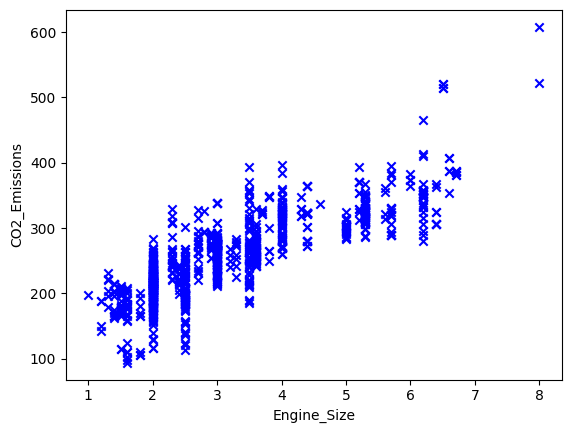

In [16]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('ida-labs/resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [24]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        list: The list of texts as strings.
    """
    df = pd.read_csv(file_path)
    texts = df.astype(str).agg(' '.join, axis=1).tolist()
    return texts

data = extract_texts_from_file('ida-labs/resources/heart.csv')
print(data[:50])

['63 1 3 145 233 1 0 150 0 2.3 0 0 1 1', '37 1 2 130 250 0 1 187 0 3.5 0 0 2 1', '41 0 1 130 204 0 0 172 0 1.4 2 0 2 1', '56 1 1 120 236 0 1 178 0 0.8 2 0 2 1', '57 0 0 120 354 0 1 163 1 0.6 2 0 2 1', '57 1 0 140 192 0 1 148 0 0.4 1 0 1 1', '56 0 1 140 294 0 0 153 0 1.3 1 0 2 1', '44 1 1 120 263 0 1 173 0 0.0 2 0 3 1', '52 1 2 172 199 1 1 162 0 0.5 2 0 3 1', '57 1 2 150 168 0 1 174 0 1.6 2 0 2 1', '54 1 0 140 239 0 1 160 0 1.2 2 0 2 1', '48 0 2 130 275 0 1 139 0 0.2 2 0 2 1', '49 1 1 130 266 0 1 171 0 0.6 2 0 2 1', '64 1 3 110 211 0 0 144 1 1.8 1 0 2 1', '58 0 3 150 283 1 0 162 0 1.0 2 0 2 1', '50 0 2 120 219 0 1 158 0 1.6 1 0 2 1', '58 0 2 120 340 0 1 172 0 0.0 2 0 2 1', '66 0 3 150 226 0 1 114 0 2.6 0 0 2 1', '43 1 0 150 247 0 1 171 0 1.5 2 0 2 1', '69 0 3 140 239 0 1 151 0 1.8 2 2 2 1', '59 1 0 135 234 0 1 161 0 0.5 1 0 3 1', '44 1 2 130 233 0 1 179 1 0.4 2 0 2 1', '42 1 0 140 226 0 1 178 0 0.0 2 0 2 1', '61 1 2 150 243 1 1 137 1 1.0 1 0 2 1', '40 1 3 140 199 0 1 178 1 1.4 2 0 3 1',

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

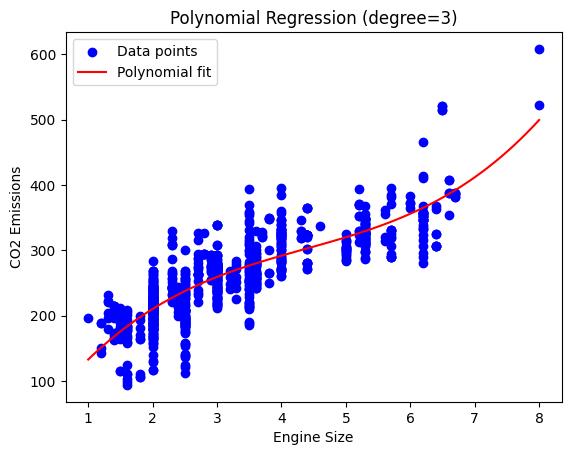

Intercept: [14.97769176]
Coefficients: [[  0.         142.13444607 -26.27884796   2.00986178]]


[np.float64(14.97769176222124),
 np.float64(142.13444606807428),
 np.float64(-26.27884796288111),
 np.float64(2.0098617768236693)]

In [38]:
def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters.
    """
    df = pd.read_csv('ida-labs/resources/CO2_emission.csv')

    x, y = df['Engine_Size'], df['CO2_Emissions']

    x_reshaped = x.values.reshape(-1, 1)
    y_reshaped = y.values.reshape(-1, 1)

    # Transform input features to polynomial features
    poly = PolynomialFeatures(degree=3)
    X_poly = poly.fit_transform(x_reshaped)

    # Fit the model
    model = LinearRegression()
    model.fit(X_poly, y_reshaped)

    # Predict and visualize
    X_plot = np.linspace(
        min(x_reshaped),
        max(x_reshaped),
        100
    ).reshape(-1, 1)

    y_pred = model.predict(poly.transform(X_plot))

    plt.scatter(x, y, color='blue', label='Data points')
    plt.plot(X_plot, y_pred, color='red', label='Polynomial fit')
    plt.xlabel('Engine Size')
    plt.ylabel('CO2 Emissions')
    plt.title('Polynomial Regression (degree=3)')
    plt.legend()
    plt.show()

    # Coefficients
    print("Intercept:", model.intercept_)
    print("Coefficients:", model.coef_)

    theta = [model.intercept_[0]] + list(model.coef_[0][1:])

    return theta


data = extract_texts_from_file('ida-labs/resources/CO2_emission.csv')
CO2_emissions(data)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

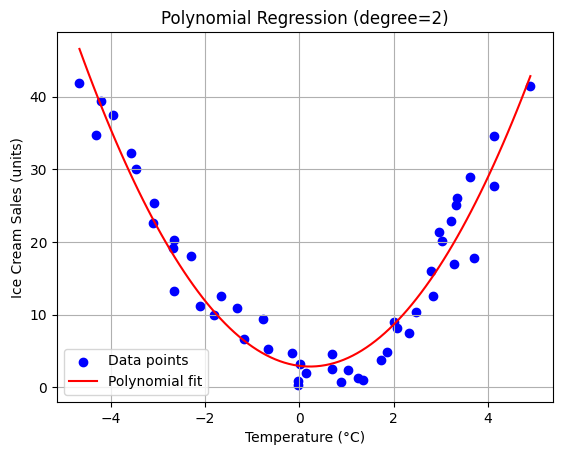

Intercept: [2.95177416]
Coefficients: [[ 0.         -0.82468167  1.82952623]]
R2 score: 0.9321137090423877


[np.float64(2.9517741579934498),
 np.float64(-0.8246816702106483),
 np.float64(1.829526229670208)]

In [40]:
def ice_cream_selling(data):
    """
    Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    df = pd.read_csv('ida-labs/resources/ice_cream_selling_data.csv')

    x, y = df['Temperature (°C)'], df['Ice Cream Sales (units)']

    x_reshaped = x.values.reshape(-1, 1)
    y_reshaped = y.values.reshape(-1, 1)

    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(x_reshaped)

    model = LinearRegression()
    model.fit(X_poly, y_reshaped)

    X_plot = np.linspace(min(x_reshaped),max(x_reshaped),100).reshape(-1, 1)
    y_pred = model.predict(poly.transform(X_plot))

    plt.scatter(x, y, color='blue', label='Data points')
    plt.plot(X_plot, y_pred, color='red', label='Polynomial fit')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('Ice Cream Sales (units)')
    plt.title('Polynomial Regression (degree=2)')
    plt.legend()
    plt.grid(True)
    plt.show()
    print("Intercept:", model.intercept_)
    print("Coefficients:", model.coef_)
    print("R2 score:", model.score(X_poly, y_reshaped))

    theta = [model.intercept_[0]] + list(model.coef_[0][1:])

    return theta

data = extract_texts_from_file('ida-labs/resources/ice_cream_selling_data.csv')
ice_cream_selling(data)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

R2 score: 0.4284591052988237
RMSE: 12996.576317107685


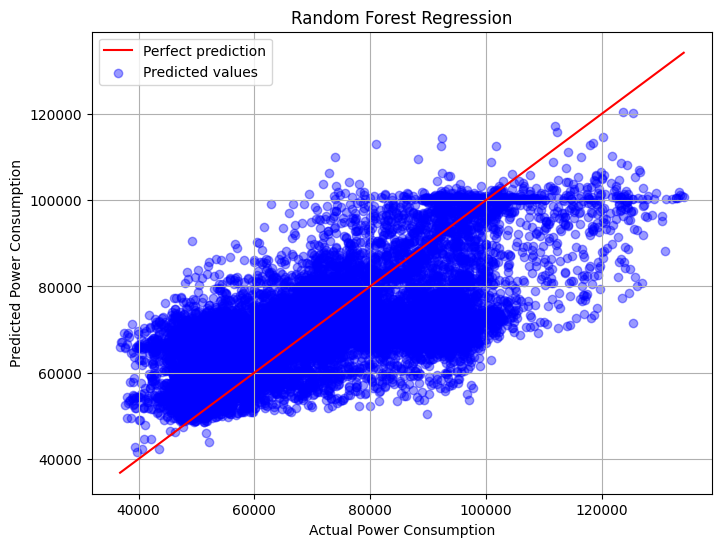

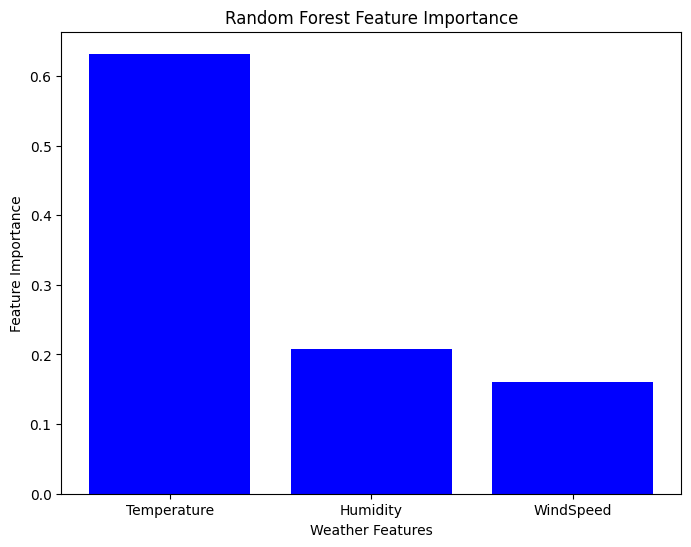

Feature Importance: [0.63188579 0.20805866 0.16005555]


In [52]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

data = pd.read_csv('ida-labs/resources/powerconsumption.csv')

X = data[['Temperature', 'Humidity', 'WindSpeed']]

# Total electricity consumption
y = (data['PowerConsumption_Zone1'] +
     data['PowerConsumption_Zone2'] +
     data['PowerConsumption_Zone3'])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    random_state=42)

# випадковий ліс
model = RandomForestRegressor(n_estimators=100,max_depth=10,random_state=42)
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)

print("R2 score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# Prediction visualization
plt.figure(figsize=(8, 6))

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot([min_val, max_val],[min_val, max_val],
         color='red',label='Perfect prediction')
plt.scatter(y_test, y_pred, color='blue', alpha=0.4,label='Predicted values')

plt.xlabel('Actual Power Consumption')
plt.ylabel('Predicted Power Consumption')
plt.title('Random Forest Regression')
plt.legend()
plt.grid(True)
plt.show()

# Feature importance
plt.figure(figsize=(8, 6))

plt.bar( X.columns,model.feature_importances_,color='blue')

plt.xlabel('Weather Features')
plt.ylabel('Feature Importance')
plt.title('Random Forest Feature Importance')
plt.show()
print("Feature Importance:", model.feature_importances_)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

Accuracy: 0.7692307692307693
ROC-AUC: 0.8653658536585366

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.66      0.72        41
           1       0.75      0.86      0.80        50

    accuracy                           0.77        91
   macro avg       0.77      0.76      0.76        91
weighted avg       0.77      0.77      0.77        91



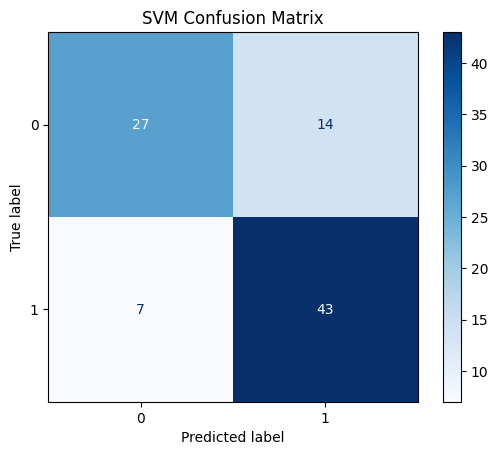

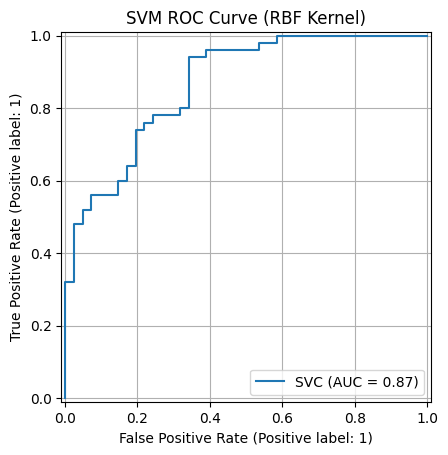

Theta: [0.07412099655944175, -0.027359634936520667, -0.3906486606342398, 0.707453587881219, -0.10698575444475782, -0.15629236824092546, -0.0063645010403483235, 0.04647502296590142, 0.33364867038495516, -0.30089266256256786, -0.37831299788332934, 0.34226480222028033, -0.4106851834227777, -0.44752939278530646]


[0.07412099655944175,
 -0.027359634936520667,
 -0.3906486606342398,
 0.707453587881219,
 -0.10698575444475782,
 -0.15629236824092546,
 -0.0063645010403483235,
 0.04647502296590142,
 0.33364867038495516,
 -0.30089266256256786,
 -0.37831299788332934,
 0.34226480222028033,
 -0.4106851834227777,
 -0.44752939278530646]

In [88]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, roc_auc_score,
                             RocCurveDisplay)

def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack.
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """
    df = pd.read_csv('ida-labs/resources/heart.csv')

    X = df.drop('output', axis=1)
    y = df['output']

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3,
        random_state=42, stratify=y
    )

    # Scale data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train SVM with RBF kernel
    clf = SVC(kernel='linear', C=0.1, probability=True, random_state=42)
    clf.fit(X_train_scaled, y_train)

    # Evaluate model
    y_pred = clf.predict(X_test_scaled)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("ROC-AUC:", roc_auc_score(
        y_test, clf.predict_proba(X_test_scaled)[:, 1]))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')

    plt.title("SVM Confusion Matrix")
    plt.show()

    # ROC Curve
    RocCurveDisplay.from_estimator(clf, X_test_scaled, y_test)

    plt.title("SVM ROC Curve (RBF Kernel)")
    plt.grid(True)
    plt.show()

    theta = [float(clf.intercept_[0])] + [float(c) for c in clf.coef_[0]]
    print("Theta:", theta)

    return theta


data = pd.read_csv('ida-labs/resources/heart.csv')
heart_classification(data)


## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

Accuracy: 0.9166666666666666
ROC-AUC: 0.9949022498873127

Classification Report:
              precision    recall  f1-score   support

       drugA       0.78      1.00      0.88         7
       drugB       1.00      1.00      1.00         5
       drugC       0.83      1.00      0.91         5
       drugX       0.94      0.94      0.94        16
       drugY       0.96      0.85      0.90        27

    accuracy                           0.92        60
   macro avg       0.90      0.96      0.92        60
weighted avg       0.92      0.92      0.92        60



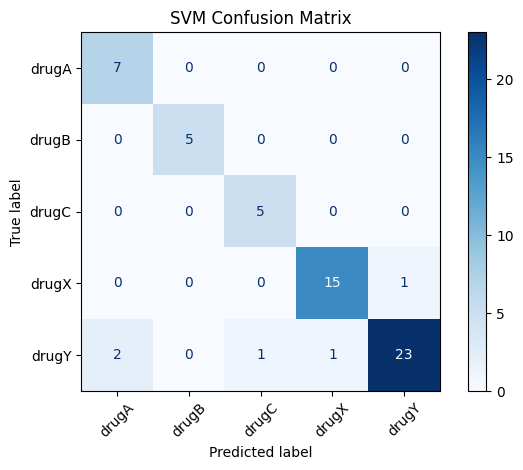

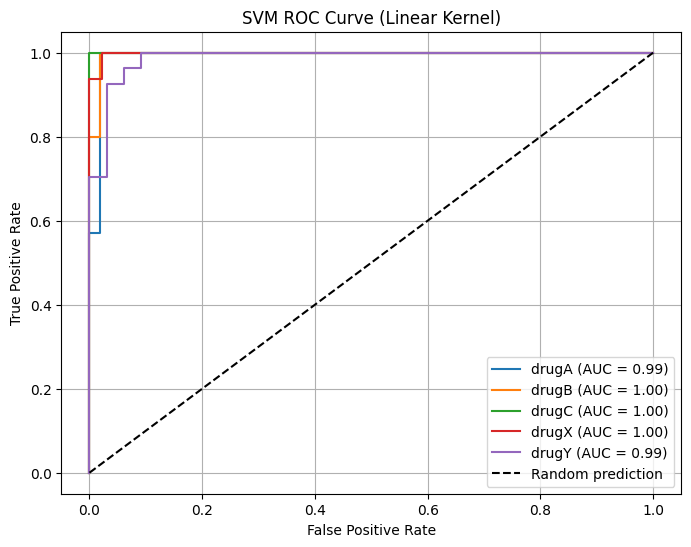

Theta: [[-0.9264499157401839, -0.1310875746392764, -0.0019124295928364676, 0.0019124295928364676, 0.0, 1.1102230246251565e-16, 1.1102230246251565e-16, 0.0019124295928364676, -0.0019124295928364121], [-0.00022572116267267905, 0.0011223099415917648, 5.504505048278818e-05, -5.504505048278818e-05, 0.46378105185024665, -0.482718623416649, 2.7755575615628914e-17, -0.00029591820772728594, 0.00029591820772728594], [-0.00017411526133595014, -0.00046964843470820306, -6.820725151318596e-06, 6.820725151318596e-06, 0.6268253727244439, -0.32611339543280354, -0.32630713756877694, 8.02350216501796e-05, -8.023502165019347e-05], [-0.26553957339489975, -1.1454526632158588, 0.005216158506055266, -0.005216158506055266, 0.27473861801808197, -0.07631212775847374, -0.2096448921758034, 0.021125740054799974, -0.021125740054799953], [0.004324972893708479, 0.006177834304941815, 0.00018843367308818762, -0.00018843367308818762, 0.46321391870877854, -0.48212833252776666, -2.7755575615628914e-17, -0.00093499531957408

In [101]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
from sklearn.metrics import (ConfusionMatrixDisplay,accuracy_score,
                             classification_report,roc_auc_score,roc_curve,auc)
def drug_classification(data):
    """
    Build a model that would classify the type of drug.
    Visualize model on a plot.

    Args:
        data: Drug medical data.

    Returns:
        list: The model coefficients.
    """

    df = data.copy()

    X = df.drop('drug', axis=1)
    y = df['drug']

    # Convert categorical features into numerical values
    X = pd.get_dummies(X,columns=['sex', 'bp', 'cholesterol'],dtype=int)

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
        random_state=42, stratify=y)
    # Scale data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train SVM with linear kernel
    clf = SVC(kernel='linear',C=0.1,probability=True,random_state=42)
    clf.fit(X_train_scaled, y_train)

    # Evaluate model
    y_pred = clf.predict(X_test_scaled)
    print("Accuracy:", accuracy_score(y_test, y_pred))

    y_proba = clf.predict_proba(X_test_scaled)

    print("ROC-AUC:", roc_auc_score(y_test,y_proba,multi_class='ovr',
                                    average='macro'))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        labels=clf.classes_,display_labels=clf.classes_,cmap='Blues',
        xticks_rotation=45)
    plt.title("SVM Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # ROC Curve for multiclass classification
    y_test_bin = label_binarize(y_test, classes=clf.classes_)
    plt.figure(figsize=(8, 6))

    for i, drug in enumerate(clf.classes_):
        fpr, tpr, _ = roc_curve(
            y_test_bin[:, i], y_proba[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr,label=f'{drug} (AUC = {roc_auc:.2f})')

    # Random prediction
    plt.plot([0, 1], [0, 1],color='black',linestyle='--',
             label='Random prediction')

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('SVM ROC Curve (Linear Kernel)')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Model parameters
    theta = clf.coef_.tolist()
    print("Theta:", theta)

    return theta

data = pd.read_csv('ida-labs/resources/drug.csv')
drug_classification(data);

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.).

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



In [ ]:
# pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter

# If loading dataset via kaggle package fails (some of these do right now when I try because of encoding issues),
# donwload the dataset manually from webpage and place csv file(s) in the resources folder.
def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df

def classify_text_ml(df):
    """
    Classify text data using a machine learning model.

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.

    Returns:
        None
    """
    # Placeholder for classification logic
    print("Classifying text data...")
    # You can implement your text classification logic here

df = load_dataset('septa97/100k-courseras-course-reviews-dataset', 'reviews.csv')
classify_text_ml(df)